# Titanic Dataset: Exploratory Data Analysis (EDA) & Data Preprocessing
Project ini bertujuan untuk menganalisis dataset Titanic dan melakukan preprocessing agar dataset siap digunakan untuk pemodelan Machine Learning dalam memprediksi kelangsungan hidup (*survival*) penumpang.

**Tahapan:** (1) Analisis deskriptif, (2) Visualisasi, (3) Insight, (4) Missing values, (5) Encoding, (6) Scaling.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
%matplotlib inline

# Load Dataset
df = pd.read_csv('train.csv')

## 1. Inspeksi Data Awal & Analisis Deskriptif
Pemeriksaan dimensi, tipe data, missing values, nilai unik, serta statistik deskriptif fitur numerik dan kategorikal.

In [3]:
print(f"Dimensi Dataset: {df.shape[0]} baris, {df.shape[1]} kolom\n")
print("--- 5 Baris Pertama Data ---")
display(df.head())

Dimensi Dataset: 891 baris, 12 kolom

--- 5 Baris Pertama Data ---


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
print("--- Informasi Tipe Data & Non-Null Count ---")
df.info()

print("\n--- Jumlah Missing Values per Kolom ---")
print(df.isnull().sum())

--- Informasi Tipe Data & Non-Null Count ---
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB

--- Jumlah Missing Values per Kolom ---
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fa

In [5]:
print("--- Jumlah Nilai Unik per Kolom ---")
print(df.nunique())

--- Jumlah Nilai Unik per Kolom ---
PassengerId    891
Survived         2
Pclass           3
Name           891
Sex              2
Age             88
SibSp            7
Parch            7
Ticket         681
Fare           248
Cabin          147
Embarked         3
dtype: int64


In [6]:
print("--- Statistik Deskriptif (Fitur Numerik) ---")
display(df.describe())

--- Statistik Deskriptif (Fitur Numerik) ---


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
print("--- Statistik Deskriptif (Fitur Kategorikal) ---")
display(df.select_dtypes(exclude='number').describe())

--- Statistik Deskriptif (Fitur Kategorikal) ---


,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


In [8]:
print("--- Distribusi Target (Survived) ---")
survived_count = df['Survived'].value_counts()
survived_pct = df['Survived'].value_counts(normalize=True) * 100
display(pd.DataFrame({'Jumlah': survived_count, 'Persentase (%)': survived_pct}))

print("\n--- Distribusi Sex dan Pclass ---")
display(df['Sex'].value_counts())
display(df['Pclass'].value_counts().sort_index())

--- Distribusi Target (Survived) ---


,Jumlah,Persentase (%)
Survived,,
0,549,61.616162
1,342,38.383838



--- Distribusi Sex dan Pclass ---


Sex
male      577
female    314
Name: count, dtype: int64

Pclass
1    216
2    184
3    491
Name: count, dtype: int64

## 2. Visualisasi Data & Hubungan Antar Fitur 
Visualisasi menggunakan **countplot**, **histogram**, **box plot**, **scatter plot**, dan **correlation heatmap**.

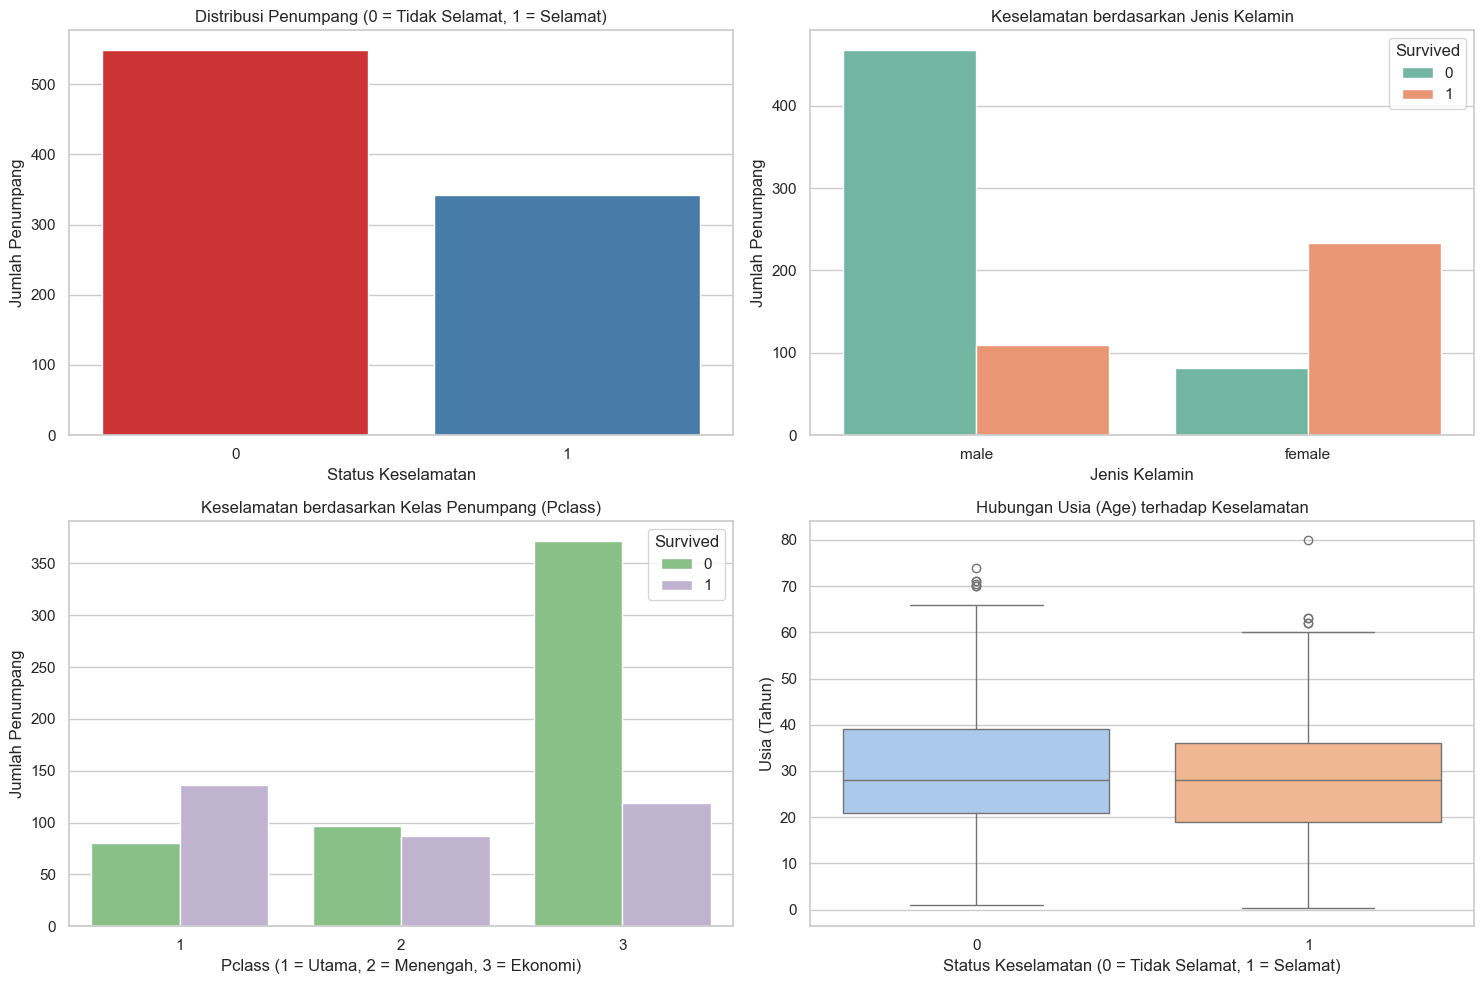

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Distribusi target
sns.countplot(data=df, x='Survived', hue='Survived', palette='Set1', legend=False, ax=axes[0, 0])
axes[0, 0].set_title('Distribusi Penumpang (0 = Tidak Selamat, 1 = Selamat)')
axes[0, 0].set_xlabel('Status Keselamatan')
axes[0, 0].set_ylabel('Jumlah Penumpang')

# Sex vs Survived
sns.countplot(data=df, x='Sex', hue='Survived', palette='Set2', ax=axes[0, 1])
axes[0, 1].set_title('Keselamatan berdasarkan Jenis Kelamin')
axes[0, 1].set_xlabel('Jenis Kelamin')
axes[0, 1].set_ylabel('Jumlah Penumpang')

# Pclass vs Survived
sns.countplot(data=df, x='Pclass', hue='Survived', palette='Accent', ax=axes[1, 0])
axes[1, 0].set_title('Keselamatan berdasarkan Kelas Penumpang (Pclass)')
axes[1, 0].set_xlabel('Pclass (1 = Utama, 2 = Menengah, 3 = Ekonomi)')
axes[1, 0].set_ylabel('Jumlah Penumpang')

# Box plot Age vs Survived
sns.boxplot(data=df, x='Survived', y='Age', hue='Survived', palette='pastel', legend=False, ax=axes[1, 1])
axes[1, 1].set_title('Hubungan Usia (Age) terhadap Keselamatan')
axes[1, 1].set_xlabel('Status Keselamatan (0 = Tidak Selamat, 1 = Selamat)')
axes[1, 1].set_ylabel('Usia (Tahun)')

plt.tight_layout()
plt.show()

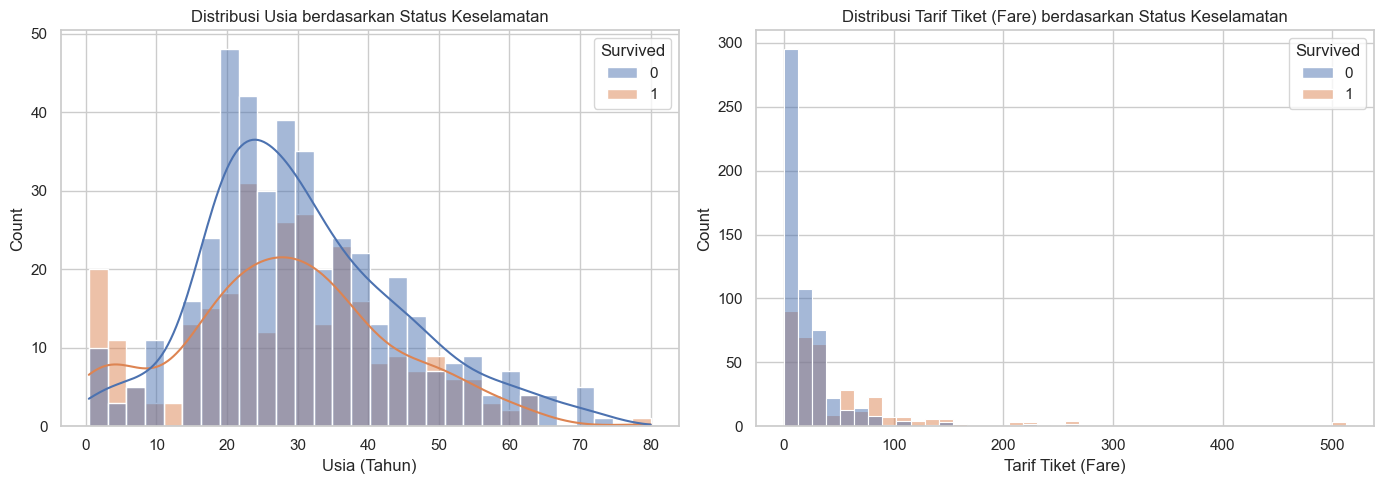

In [10]:
# Histogram Age dan Fare
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df, x='Age', hue='Survived', bins=30, kde=True, ax=axes[0])
axes[0].set_title('Distribusi Usia berdasarkan Status Keselamatan')
axes[0].set_xlabel('Usia (Tahun)')

sns.histplot(data=df, x='Fare', hue='Survived', bins=40, ax=axes[1])
axes[1].set_title('Distribusi Tarif Tiket (Fare) berdasarkan Status Keselamatan')
axes[1].set_xlabel('Tarif Tiket (Fare)')

plt.tight_layout()
plt.show()

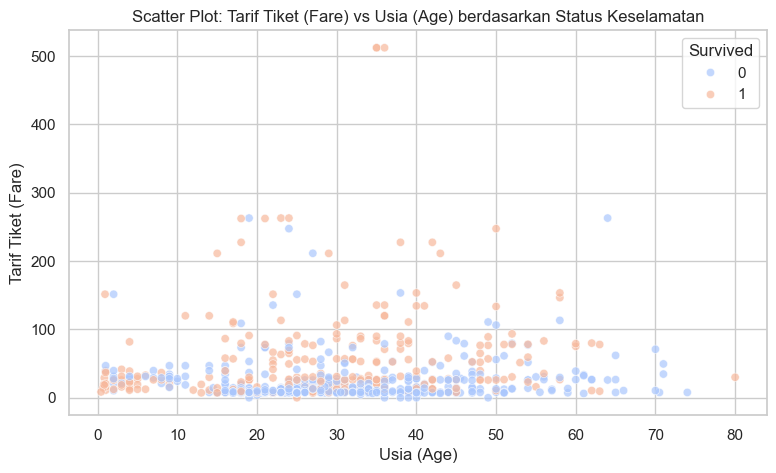

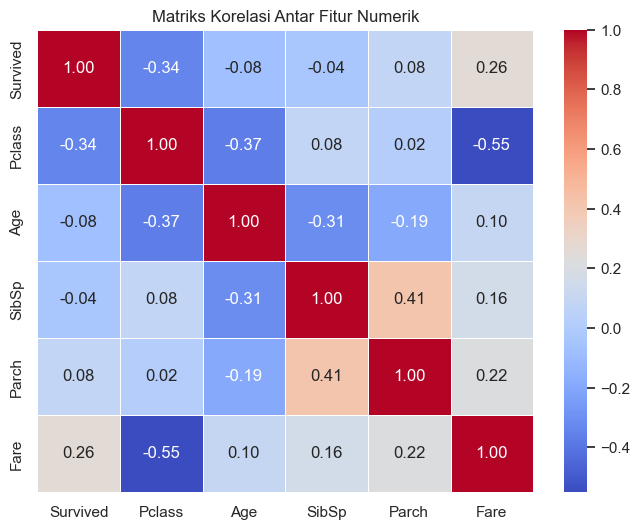

In [11]:
# Scatter plot Fare vs Age
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x='Age', y='Fare', hue='Survived', alpha=0.7, palette='coolwarm')
plt.title('Scatter Plot: Tarif Tiket (Fare) vs Usia (Age) berdasarkan Status Keselamatan')
plt.xlabel('Usia (Age)')
plt.ylabel('Tarif Tiket (Fare)')
plt.show()

# Correlation heatmap (PassengerId dibuang karena hanya ID)
plt.figure(figsize=(8, 6))
corr = df.drop(columns='PassengerId').select_dtypes(include='number').corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Matriks Korelasi Antar Fitur Numerik')
plt.show()

## 3. Rangkuman Insight Utama dari EDA 
Sebelum menyimpulkan, kita hitung dulu angka survival rate per kelompok agar insight didukung data.

In [12]:
# Kelompok usia dibuat sebagai Series terpisah 
age_group = pd.cut(df['Age'], bins=[0, 12, 18, 60, 100],
                   labels=['Anak (<=12)', 'Remaja (13-18)', 'Dewasa (19-60)', 'Lansia (>60)'])

print("--- Survival Rate (%) berdasarkan Sex ---")
print((df.groupby('Sex')['Survived'].mean() * 100).round(1))

print("\n--- Survival Rate (%) berdasarkan Pclass ---")
print((df.groupby('Pclass')['Survived'].mean() * 100).round(1))

print("\n--- Survival Rate (%) berdasarkan Kelompok Usia ---")
print((df.groupby(age_group, observed=True)['Survived'].mean() * 100).round(1))

print("\n--- Rata-rata Fare berdasarkan Pclass ---")
print(df.groupby('Pclass')['Fare'].mean().round(2))

print("\n--- Rata-rata Fare berdasarkan Survived ---")
print(df.groupby('Survived')['Fare'].mean().round(2))

print(f"\nSkewness Fare: {df['Fare'].skew():.2f}")

--- Survival Rate (%) berdasarkan Sex ---
Sex
female    74.2
male      18.9
Name: Survived, dtype: float64

--- Survival Rate (%) berdasarkan Pclass ---
Pclass
1    63.0
2    47.3
3    24.2
Name: Survived, dtype: float64

--- Survival Rate (%) berdasarkan Kelompok Usia ---
Age
Anak (<=12)       58.0
Remaja (13-18)    42.9
Dewasa (19-60)    38.9
Lansia (>60)      22.7
Name: Survived, dtype: float64

--- Rata-rata Fare berdasarkan Pclass ---
Pclass
1    84.15
2    20.66
3    13.68
Name: Fare, dtype: float64

--- Rata-rata Fare berdasarkan Survived ---
Survived
0    22.12
1    48.40
Name: Fare, dtype: float64

Skewness Fare: 4.79


**Insight utama:**

1. **Sex (fitur paling kuat):** Perempuan selamat **74.2%**, sedangkan laki-laki hanya **18.9%**. Selisihnya sangat besar sehingga Sex hampir pasti menjadi prediktor terpenting.
2. **Pclass:** Survival rate menurun seiring turunnya kelas: Kelas 1 **63.0%**, Kelas 2 **47.3%**, Kelas 3 **24.2%**. Status sosial-ekonomi berhubungan kuat dengan peluang selamat.
3. **Fare:** Distribusinya sangat *right-skewed* dengan outlier (median sekitar 14.45, maksimum 512.33). Rata-rata Fare berbeda jauh antar Pclass (lihat output di atas), dan penumpang yang selamat rata-rata membayar tarif lebih tinggi. Jadi Fare berkaitan erat dengan Pclass dan ikut membawa informasi tentang peluang selamat.
4. **Age:** Anak-anak (<=12 tahun) memiliki survival rate **58.0%**, lebih tinggi dibanding dewasa (**38.9%**) dan lansia (**22.7%**). Usia punya pengaruh, tetapi lebih lemah dibanding Sex dan Pclass.
5. **Korelasi:** Pada heatmap, Pclass dan Fare berkorelasi negatif (kelas lebih tinggi = tarif lebih mahal), sehingga kedua fitur ini membawa informasi yang tumpang tindih.

## 4. Data Preprocessing: Cleaning & Handling Missing Values

### Strategi Penanganan Data
- **Cabin:** *Missing* sekitar 77%. Terlalu banyak yang kosong dan sulit diimputasi secara objektif, sehingga kolom ini **dihapus**.
- **PassengerId, Name, Ticket:** Merupakan identifier unik (teks bebas) yang tidak punya nilai prediktif generik, sehingga **dihapus**.
- **Age:** *Missing* sekitar 19.9%. Diimputasi dengan **median per kelompok Pclass dan Sex**. Median dipilih karena tidak sensitif terhadap outlier, dan pengelompokan membuat nilai lebih mewakili karakteristik penumpang.
- **Embarked:** Hanya 2 nilai hilang. Diimputasi dengan **modus** (lokasi keberangkatan paling umum).

In [13]:
# 1. Hapus kolom Cabin dan identifier unik
df_clean = df.drop(columns=['Cabin', 'PassengerId', 'Name', 'Ticket'])

# 2. Imputasi Age dengan median per (Pclass, Sex)
df_clean['Age'] = df_clean.groupby(['Pclass', 'Sex'])['Age'].transform(lambda x: x.fillna(x.median()))

# 3. Imputasi Embarked dengan modus
mode_embarked = df_clean['Embarked'].mode()[0]
df_clean['Embarked'] = df_clean['Embarked'].fillna(mode_embarked)

print(f"Modus Embarked: {mode_embarked}")
print("\n--- Check Sisa Missing Values ---")
print(df_clean.isnull().sum())

Modus Embarked: S

--- Check Sisa Missing Values ---
Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


## 5. Data Preprocessing: Categorical Encoding 

### Strategi Encoding
- **Sex & Embarked:** Fitur kategorikal **nominal** (tidak ada tingkatan). Digunakan **One-Hot Encoding** (`pd.get_dummies`, `drop_first=True`). Jika diberi label 0, 1, 2 (label encoding), model akan mengira ada urutan atau jarak antar kategori. Pembuangan satu kolom (`drop_first`) menghindari *dummy variable trap* (multikolinearitas).
- **Pclass:** Bersifat **ordinal** (1 > 2 > 3) dan sudah numerik berurutan, sehingga tidak perlu di-encode lagi.

In [14]:
df_encoded = pd.get_dummies(df_clean, columns=['Sex', 'Embarked'], drop_first=True, dtype=int)

print("--- Data Setelah Categorical Encoding ---")
display(df_encoded.head())

--- Data Setelah Categorical Encoding ---


,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,0,3,22.0,1,0,7.2500,1,0,1
1,1,1,38.0,1,0,71.2833,0,0,0
2,1,3,26.0,0,0,7.9250,0,0,1
3,1,1,35.0,1,0,53.1000,0,0,1
4,0,3,35.0,0,0,8.0500,1,0,1


## 6. Data Preprocessing: Feature Scaling 

### Strategi Feature Scaling
- Digunakan **StandardScaler** (Z-score: z = (x - mean) / std) pada fitur numerik kontinu **Age** dan **Fare**, sehingga keduanya memiliki mean = 0 dan standar deviasi = 1.
- **Alasan:** Skala kedua fitur sangat berbeda (Fare 0 sampai 512, Age 0.42 sampai 80). Pada algoritma **berbasis jarak** (KNN, SVM) fitur berskala besar akan mendominasi perhitungan jarak. Pada **Logistic Regression**, skala yang berbeda memperlambat konvergensi *gradient descent* dan membuat regularisasi tidak adil antar fitur. Model berbasis pohon (Decision Tree, Random Forest) sebenarnya tidak memerlukan scaling.
- **Fitur yang tidak di-scale:** Pclass, SibSp, Parch, dan kolom hasil One-Hot (0/1) karena rentangnya sudah kecil.
- **Catatan:** Fare bersifat skewed dan memiliki outlier, padahal StandardScaler sensitif terhadap outlier. Alternatifnya adalah RobustScaler atau transformasi log1p. StandardScaler tetap dipilih karena sederhana dan cukup untuk tahap ini.
- **Catatan modeling:** Pada tahap modeling, scaler sebaiknya di-*fit* hanya pada data train lalu di-*transform* ke data test, agar tidak terjadi *data leakage*.

In [15]:
scaler = StandardScaler()
df_final = df_encoded.copy()

num_cols = ['Age', 'Fare']
df_final[num_cols] = scaler.fit_transform(df_encoded[num_cols])

print("--- DataFrame Final ---")
display(df_final.head())

print("\n--- Verifikasi hasil scaling (mean ~ 0, std ~ 1) ---")
display(df_final[num_cols].agg(['mean', 'std']).round(3))

print("\nInformasi Tipe Data Final:")
df_final.info()

--- DataFrame Final ---


,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,0,3,-0.534891,1,0,-0.502445,1,0,1
1,1,1,0.668392,1,0,0.786845,0,0,0
2,1,3,-0.234070,0,0,-0.488854,0,0,1
3,1,1,0.442776,1,0,0.420730,0,0,1
4,0,3,0.442776,0,0,-0.486337,1,0,1



--- Verifikasi hasil scaling (mean ~ 0, std ~ 1) ---


,Age,Fare
mean,0.000,0.000
std,1.001,1.001



Informasi Tipe Data Final:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Survived    891 non-null    int64  
 1   Pclass      891 non-null    int64  
 2   Age         891 non-null    float64
 3   SibSp       891 non-null    int64  
 4   Parch       891 non-null    int64  
 5   Fare        891 non-null    float64
 6   Sex_male    891 non-null    int64  
 7   Embarked_Q  891 non-null    int64  
 8   Embarked_S  891 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 62.8 KB


In [16]:
# Validasi akhir: tidak ada missing value dan semua kolom numerik
assert df_final.isnull().sum().sum() == 0, "Masih ada missing value!"
assert all(pd.api.types.is_numeric_dtype(t) for t in df_final.dtypes), "Masih ada kolom non-numerik!"
print(f"Dataset siap untuk pemodelan: {df_final.shape[0]} baris, {df_final.shape[1]} kolom")

Dataset siap untuk pemodelan: 891 baris, 9 kolom


## 7. Persiapan Modeling: Pemilihan Fitur & Split Data 70:30

### Fitur yang dipilih
Fitur yang dipakai: Pclass, Age, SibSp, Parch, Fare, Sex_male, Embarked_Q, Embarked_S. Berdasarkan EDA, Sex, Pclass, Age, dan Fare terbukti berhubungan dengan survival. SibSp, Parch, dan Embarked tetap dimasukkan sebagai fitur pendukung. Kolom PassengerId, Name, Ticket, dan Cabin sudah dibuang di tahap preprocessing.

### Split data
Data dibagi **70% train : 30% test** dengan stratify=y, supaya proporsi selamat/tidak selamat di train dan test sama dengan data asli (38.4% / 61.6%).

### Mencegah data leakage
Di Section 6, scaler di-fit ke seluruh data (cukup untuk tahap preprocessing). Untuk modeling, scaling diulang dari df_encoded: **scaler di-fit hanya pada data train**, lalu di **transform** ke data test. Dengan begitu informasi dari data test tidak bocor ke proses training.

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

features = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_Q', 'Embarked_S']
X = df_encoded[features]
y = df_encoded['Survived']

# Split 70:30 (stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

print(f"Data train: {X_train.shape[0]} baris ({X_train.shape[0]/len(X)*100:.0f}%)")
print(f"Data test : {X_test.shape[0]} baris ({X_test.shape[0]/len(X)*100:.0f}%)")
print("\nProporsi Survived (%) di train:")
print((y_train.value_counts(normalize=True) * 100).round(1))
print("\nProporsi Survived (%) di test:")
print((y_test.value_counts(normalize=True) * 100).round(1))

Data train: 623 baris (70%)
Data test : 268 baris (30%)

Proporsi Survived (%) di train:
Survived
0    61.6
1    38.4
Name: proportion, dtype: float64

Proporsi Survived (%) di test:
Survived
0    61.6
1    38.4
Name: proportion, dtype: float64


In [18]:
# Scaling: fit hanya pada data train, transform ke train dan test
num_cols = ['Age', 'Fare']
model_scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[num_cols] = model_scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = model_scaler.transform(X_test[num_cols])

display(X_train_scaled.head())

,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
748,1,-0.782506,1,0,0.465738,1,0,1
45,3,-0.332603,0,0,-0.478269,1,0,1
28,3,-0.595047,0,0,-0.481848,0,1,0
633,1,0.792154,0,0,-0.646954,1,0,1
403,3,-0.107652,1,0,-0.314823,1,0,1


## 8. Training Model Logistic Regression

In [19]:
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

# Koefisien model + odds ratio (exp(koefisien)) untuk interpretasi
coef_df = pd.DataFrame({
    'Fitur': features,
    'Koefisien': log_reg.coef_[0],
    'Odds Ratio': np.exp(log_reg.coef_[0])
}).sort_values('Koefisien', ascending=False).reset_index(drop=True)

print(f"Intercept: {log_reg.intercept_[0]:.3f}\n")
display(coef_df.round(3))

Intercept: 4.049



,Fitur,Koefisien,Odds Ratio
0,Embarked_Q,0.218,1.243
1,Fare,0.116,1.123
2,Parch,-0.043,0.958
3,Embarked_S,-0.264,0.768
4,SibSp,-0.322,0.725
5,Age,-0.616,0.540
6,Pclass,-1.169,0.311
7,Sex_male,-2.523,0.080


## 9. Evaluasi Model (Accuracy, Precision, Recall, ROC-AUC)
Kelas positif = **1 (Selamat)**. Prediksi memakai threshold default 0.5.

In [20]:
y_pred = log_reg.predict(X_test_scaled)
y_proba = log_reg.predict_proba(X_test_scaled)[:, 1]

metrics = pd.DataFrame({
    'Metrik': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    'Skor': [accuracy_score(y_test, y_pred),
             precision_score(y_test, y_pred),
             recall_score(y_test, y_pred),
             f1_score(y_test, y_pred),
             roc_auc_score(y_test, y_proba)]
})
display(metrics.round(4))

# Cek overfitting: bandingkan akurasi train vs test
train_acc = accuracy_score(y_train, log_reg.predict(X_train_scaled))
test_acc = accuracy_score(y_test, y_pred)
print(f"Akurasi Train: {train_acc:.4f}")
print(f"Akurasi Test : {test_acc:.4f}")
print(f"Selisih      : {abs(train_acc - test_acc):.4f}")

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=['Tidak Selamat (0)', 'Selamat (1)']))

,Metrik,Skor
0,Accuracy,0.8097
1,Precision,0.7653
2,Recall,0.7282
3,F1-Score,0.7463
4,ROC-AUC,0.8499


Akurasi Train: 0.8090
Akurasi Test : 0.8097
Selisih      : 0.0007

--- Classification Report ---
                   precision    recall  f1-score   support

Tidak Selamat (0)       0.84      0.86      0.85       165
      Selamat (1)       0.77      0.73      0.75       103

         accuracy                           0.81       268
        macro avg       0.80      0.79      0.80       268
     weighted avg       0.81      0.81      0.81       268



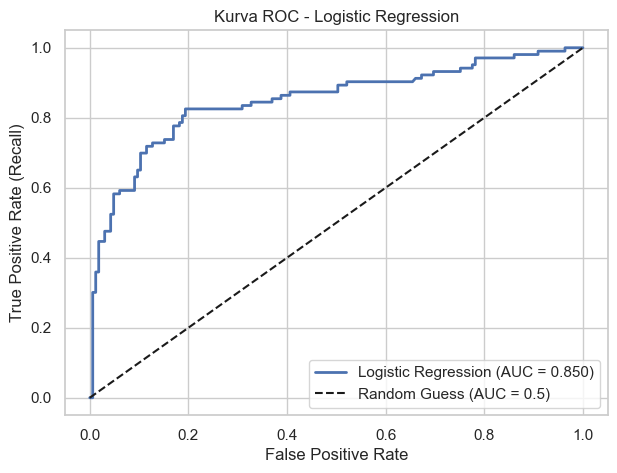

In [21]:
# Kurva ROC
fpr, tpr, _ = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, linewidth=2, label=f'Logistic Regression (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess (AUC = 0.5)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('Kurva ROC - Logistic Regression')
plt.legend(loc='lower right')
plt.show()

## 10. Analisis Confusion Matrix

| | Prediksi: Tidak Selamat (0) | Prediksi: Selamat (1) |
|---|---|---|
| **Aktual: Tidak Selamat (0)** | **TN** (True Negative) | **FP** (False Positive) |
| **Aktual: Selamat (1)** | **FN** (False Negative) | **TP** (True Positive) |

- **TP:** penumpang yang selamat dan diprediksi selamat.
- **TN:** penumpang yang tidak selamat dan diprediksi tidak selamat.
- **FP:** penumpang yang sebenarnya tidak selamat tetapi diprediksi selamat (model terlalu optimis).
- **FN:** penumpang yang sebenarnya selamat tetapi diprediksi tidak selamat (model melewatkan penyintas).

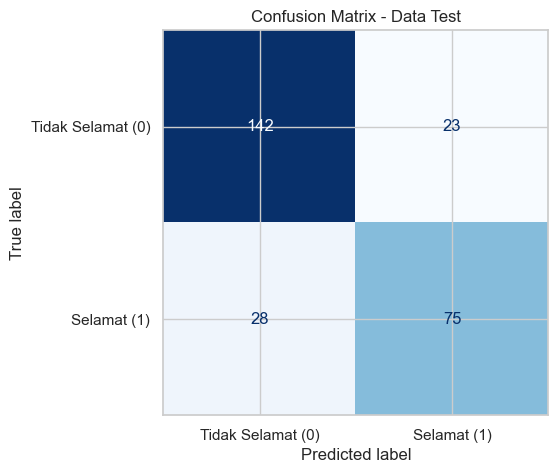

True Negative  (TN):  142  -> tidak selamat & diprediksi tidak selamat
False Positive (FP):   23  -> tidak selamat tapi diprediksi selamat
False Negative (FN):   28  -> selamat tapi diprediksi tidak selamat
True Positive  (TP):   75  -> selamat & diprediksi selamat

Prediksi benar : 217 dari 268 (81.0%)
Prediksi salah : 51 dari 268 (19.0%)

--- Turunan metrik dari confusion matrix ---
Precision   = TP / (TP + FP) = 75/98 = 0.765  -> dari semua yang diprediksi selamat, 76.5% benar-benar selamat
Recall      = TP / (TP + FN) = 75/103 = 0.728  -> dari semua penyintas asli, 72.8% berhasil terdeteksi
Specificity = TN / (TN + FP) = 142/165 = 0.861  -> dari semua korban asli, 86.1% berhasil terdeteksi


In [22]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=['Tidak Selamat (0)', 'Selamat (1)']).plot(
    ax=ax, cmap='Blues', values_format='d', colorbar=False)
ax.set_title('Confusion Matrix - Data Test')
plt.show()

total = cm.sum()
print(f"True Negative  (TN): {tn:>4}  -> tidak selamat & diprediksi tidak selamat")
print(f"False Positive (FP): {fp:>4}  -> tidak selamat tapi diprediksi selamat")
print(f"False Negative (FN): {fn:>4}  -> selamat tapi diprediksi tidak selamat")
print(f"True Positive  (TP): {tp:>4}  -> selamat & diprediksi selamat")
print(f"\nPrediksi benar : {tn + tp} dari {total} ({(tn + tp) / total * 100:.1f}%)")
print(f"Prediksi salah : {fp + fn} dari {total} ({(fp + fn) / total * 100:.1f}%)")

print("\n--- Turunan metrik dari confusion matrix ---")
print(f"Precision   = TP / (TP + FP) = {tp}/{tp + fp} = {tp / (tp + fp):.3f}  "
      f"-> dari semua yang diprediksi selamat, {tp / (tp + fp) * 100:.1f}% benar-benar selamat")
print(f"Recall      = TP / (TP + FN) = {tp}/{tp + fn} = {tp / (tp + fn):.3f}  "
      f"-> dari semua penyintas asli, {tp / (tp + fn) * 100:.1f}% berhasil terdeteksi")
print(f"Specificity = TN / (TN + FP) = {tn}/{tn + fp} = {tn / (tn + fp):.3f}  "
      f"-> dari semua korban asli, {tn / (tn + fp) * 100:.1f}% berhasil terdeteksi")